# 10 · Additional evaluation: known-attack CV, FPR at 95% recall, missed records, compute cost

Three analyses promised in the project proposal, computed **without re-tuning or replacing any model**:

1. **Known-attack performance.** Stratified 5-fold CV on `KDDTrain+` (seed 42) for each model, using the hyperparameters already selected in notebooks 04–07. Every fold sees every attack type, so this measures performance on *known* attacks. The final saved models and all KDDTest+ results are untouched; the fold models are evaluation-only and are not saved. Comparing this with unseen-attack performance on `KDDTest+` gives the known-vs-unseen gap exactly as the proposal defined it.
2. **FPR at 95% recall.** The false-positive rate each model needs to catch 95% of attacks, on the test set (all, seen and unseen attacks) and in the known-attack CV. Computed from the saved predictions.
3. **Representative missed records.** For each unseen attack type, a few test flows that the models miss, with key feature values and each model's P(attack), for the website's error inspector.
4. **Actual vs predicted.** Actual attacks per group (Normal, DoS, Probe, R2L, U2R, unseen types) next to each model's predicted attacks, at threshold 0.5 and at fixed test-FPR operating points.
5. **Compute cost.** Tuning time (from the Optuna logs), final fit time, model size on disk, and inference latency measured on the saved models (median of repeated runs): per flow in a batch, and for a single flow as a live system would see it. Nothing is trained here.

**Outputs:** `results/metrics/additional_evaluation.json`, `results/tables/known_cv.*`, `results/tables/known_vs_unseen_gap.*`, `results/tables/fpr_at_95_recall.*`, `results/tables/missed_records.csv`, `results/tables/compute_cost.*`, `results/figures/additional/*.png`.

In [1]:
import sys, json, time, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from src.config import set_all_seeds
from src import controlled_framework as cf

rng = set_all_seeds(cf.SEED)
sns.set_theme(style="whitegrid", context="notebook")
data = cf.load_dataset()
MODELS = {"Logistic Regression": ("logistic_regression", LogisticRegression),
          "Decision Tree": ("decision_tree", DecisionTreeClassifier),
          "Random Forest": ("random_forest", RandomForestClassifier),
          "XGBoost": ("xgboost", XGBClassifier)}
COLORS = {"Logistic Regression": "#3F6390", "Decision Tree": "#5E7F2E", "Random Forest": "#8E2C4C", "XGBoost": "#B9792A"}
print("models:", list(MODELS), "| seed", cf.SEED)

models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'] | seed 42


## Helpers

In [2]:
def fpr_at_recall(y, s, target=0.95):
    """Smallest FPR whose threshold still catches >= target of positives (attack if score > t)."""
    y, s = np.asarray(y), np.asarray(s, dtype=float)
    pos, neg = np.sort(s[y == 1]), np.sort(s[y == 0])
    cand = np.r_[-np.inf, np.unique(s)]
    recall = (len(pos) - np.searchsorted(pos, cand, side="right")) / len(pos)
    t = cand[np.flatnonzero(recall >= target)[-1]]
    return float((len(neg) - np.searchsorted(neg, t, side="right")) / len(neg)), float(t)

def recall_at_fpr(y, s, budget):
    y, s = np.asarray(y), np.asarray(s, dtype=float)
    t = cf.threshold_for_fpr(s[y == 0], budget)
    return float((s[y == 1] > t).mean())

FPR_GRID = np.unique(np.round(np.r_[np.linspace(0, 0.2, 81), np.linspace(0.2, 1, 33)], 4))   # same grid as notebook 11
assert fpr_at_recall([0, 0, 1, 1], [0.1, 0.6, 0.5, 0.9], 0.95)[0] == 0.5

## 1. Known-attack performance: stratified 5-fold CV on `KDDTrain+`

Same folds for every model (`StratifiedKFold(5, shuffle=True, random_state=42)`); the preprocessor is refit inside every fold; hyperparameters are the seed-42 tuned values from `results/tuning/*_trials.json`.

In [3]:
y_tr = data.y_train.to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=cf.SEED).split(data.X_train, data.y_train))
known, oof = {}, {}
for name, (key, Est) in MODELS.items():
    params = json.loads((cf.TUNING_DIR / f"{key}_trials.json").read_text())["best_params"]
    scores, fold_auc, t0 = np.empty(len(y_tr)), [], time.perf_counter()
    for tr, va in folds:
        pipe = cf.make_pipeline(lambda p, E=Est: E(**p), params, data.X_train.iloc[tr])
        pipe.fit(data.X_train.iloc[tr], data.y_train.iloc[tr])
        scores[va] = pipe.predict_proba(data.X_train.iloc[va])[:, 1]
        fold_auc.append(roc_auc_score(y_tr[va], scores[va]))
    oof[name] = scores
    pred = (scores > cf.THRESHOLD).astype(int)
    known[name] = {
        "roc_auc": float(roc_auc_score(y_tr, scores)), "roc_auc_fold_mean": float(np.mean(fold_auc)), "roc_auc_fold_std": float(np.std(fold_auc)),
        "pr_auc": float(average_precision_score(y_tr, scores)),
        **{f"recall_at_fpr_{b * 100:g}pct": recall_at_fpr(y_tr, scores, b) for b in cf.FPR_BUDGETS},
        "fpr_at_95_recall": fpr_at_recall(y_tr, scores)[0],
        "macro_f1_at_0.5": float(f1_score(y_tr, pred, average="macro")),
        "attack_recall_at_0.5": float(pred[y_tr == 1].mean()), "fpr_at_0.5": float(pred[y_tr == 0].mean()),
        "cv_seconds": round(time.perf_counter() - t0, 1),
    }
    print(f"{name:20s} known CV ROC-AUC {known[name]['roc_auc']:.4f} (fold SD {known[name]['roc_auc_fold_std']:.4f}) "
          f"| FPR@95%recall {100 * known[name]['fpr_at_95_recall']:.2f}% | {known[name]['cv_seconds']} s")
known_tbl = pd.DataFrame(known).T.reset_index(names="model")
cf.save_table(known_tbl, "known_cv")
known_tbl

Logistic Regression  known CV ROC-AUC 0.9924 (fold SD 0.0006) | FPR@95%recall 1.99% | 6.7 s


Decision Tree        known CV ROC-AUC 0.9988 (fold SD 0.0002) | FPR@95%recall 0.37% | 4.3 s


Random Forest        known CV ROC-AUC 1.0000 (fold SD 0.0000) | FPR@95%recall 0.00% | 15.2 s


XGBoost              known CV ROC-AUC 0.9998 (fold SD 0.0000) | FPR@95%recall 0.00% | 15.8 s


,model,roc_auc,roc_auc_fold_mean,roc_auc_fold_std,pr_auc,recall_at_fpr_1pct,recall_at_fpr_2pct,recall_at_fpr_5pct,fpr_at_95_recall,macro_f1_at_0.5,attack_recall_at_0.5,fpr_at_0.5,cv_seconds
0,Logistic Regression,0.992366,0.992368,0.000646,0.992780,0.937319,0.950128,0.974979,0.019854,0.965271,0.952891,0.023551,6.7
1,Decision Tree,0.998776,0.998655,0.000152,0.998545,0.978236,0.985434,0.996384,0.003712,0.985025,0.978202,0.008880,4.3
2,Random Forest,0.999991,0.999991,0.000003,0.999990,0.999881,0.999983,0.999983,0.000000,0.998700,0.997749,0.000460,15.2
3,XGBoost,0.999803,0.999803,0.000048,0.999796,0.997663,0.997919,0.998687,0.000045,0.996386,0.994167,0.001648,15.8


## 2. Known vs unseen gap (as defined in the proposal)

*Known* = stratified CV on `KDDTrain+` (attack types seen in training, training normals). *Unseen* = the 17 test-only attack types against the test normals, from the saved seed-42 predictions.

In [4]:
preds = {name: pd.read_csv(cf.PRED_DIR / f"{key}_predictions.csv") for name, (key, _) in MODELS.items()}
test_metrics = {name: json.loads((cf.METRICS_DIR / f"{key}.json").read_text()) for name, (key, _) in MODELS.items()}
gap_rows = []
for name in MODELS:
    p = preds[name]
    norm, unseen = p.y_true.to_numpy() == 0, (p.y_true.to_numpy() == 1) & p.is_unseen.to_numpy()
    m = norm | unseen
    yu, su = p.y_true.to_numpy()[m], p.y_prob.to_numpy()[m]
    tf, ops = test_metrics[name]["threshold_free"], test_metrics[name]["test_roc_operating_points"]
    gap_rows.append({
        "model": name,
        "known_roc_auc": known[name]["roc_auc"], "unseen_roc_auc": tf["roc_auc_unseen_vs_normal"],
        "known_recall_at_fpr_1pct": known[name]["recall_at_fpr_1pct"], "unseen_recall_at_fpr_1pct": ops["fpr_1pct"]["unseen_recall"],
        "known_recall_at_fpr_5pct": known[name]["recall_at_fpr_5pct"], "unseen_recall_at_fpr_5pct": ops["fpr_5pct"]["unseen_recall"],
        "known_attack_recall_at_0.5": known[name]["attack_recall_at_0.5"], "unseen_recall_at_0.5": test_metrics[name]["seen_vs_unseen_recall"]["unseen_recall"],
        "known_fpr_at_95_recall": known[name]["fpr_at_95_recall"], "unseen_fpr_at_95_recall": fpr_at_recall(yu, su)[0],
    })
gap = pd.DataFrame(gap_rows)
gap["auc_gap"] = gap.known_roc_auc - gap.unseen_roc_auc
gap["recall_gap_at_fpr_1pct_pp"] = 100 * (gap.known_recall_at_fpr_1pct - gap.unseen_recall_at_fpr_1pct)
gap["recall_gap_at_0.5_pp"] = 100 * (gap["known_attack_recall_at_0.5"] - gap["unseen_recall_at_0.5"])
cf.save_table(gap, "known_vs_unseen_gap")
gap.set_index("model").T.round(4)

model,Logistic Regression,Decision Tree,Random Forest,XGBoost
known_roc_auc,0.9924,0.9988,1.0000,0.9998
unseen_roc_auc,0.8831,0.7336,0.9417,0.9466
known_recall_at_fpr_1pct,0.9373,0.9782,0.9999,0.9977
unseen_recall_at_fpr_1pct,0.0523,0.0667,0.0717,0.0515
known_recall_at_fpr_5pct,0.9750,0.9964,1.0000,0.9987
unseen_recall_at_fpr_5pct,0.0720,0.3563,0.6333,0.8216
known_attack_recall_at_0.5,0.9529,0.9782,0.9977,0.9942
unseen_recall_at_0.5,0.2955,0.3496,0.2461,0.2832
known_fpr_at_95_recall,0.0199,0.0037,0.0000,0.0000
unseen_fpr_at_95_recall,0.2294,1.0000,0.1249,0.1920


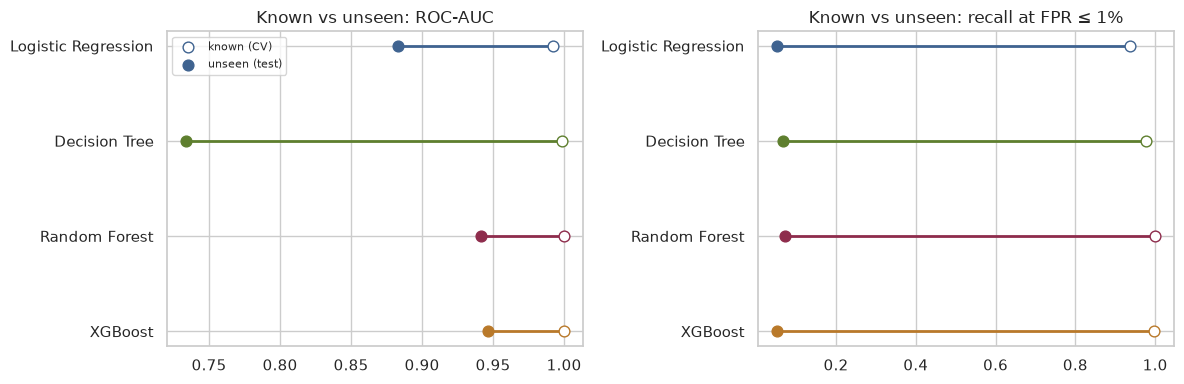

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (k, u, title) in zip(axes, [("known_roc_auc", "unseen_roc_auc", "ROC-AUC"),
                                     ("known_recall_at_fpr_1pct", "unseen_recall_at_fpr_1pct", "recall at FPR ≤ 1%")]):
    for i, r in gap.iterrows():
        ax.plot([r[k], r[u]], [i, i], color=COLORS[r.model], lw=2)
        ax.scatter([r[k]], [i], facecolor="white", edgecolor=COLORS[r.model], s=60, zorder=3, label="known (CV)" if i == 0 else None)
        ax.scatter([r[u]], [i], color=COLORS[r.model], s=60, zorder=3, label="unseen (test)" if i == 0 else None)
    ax.set_yticks(range(len(gap)), gap.model); ax.set_title(f"Known vs unseen: {title}"); ax.invert_yaxis()
axes[0].legend(fontsize=8)
fig.tight_layout(); cf.save_figure(fig, "additional", "known_vs_unseen_gap"); plt.show()

## 3. FPR at 95% recall on `KDDTest+`

In [6]:
fpr95_rows = []
for name in MODELS:
    p = preds[name]
    y, s, u = p.y_true.to_numpy(), p.y_prob.to_numpy(), p.is_unseen.to_numpy()
    row = {"model": name, "known_cv": known[name]["fpr_at_95_recall"]}
    for subset, mask in {"test_all": y == 1, "test_seen": (y == 1) & ~u, "test_unseen": (y == 1) & u}.items():
        sel = (y == 0) | mask
        row[subset] = fpr_at_recall(y[sel], s[sel])[0]
    fpr95_rows.append(row)
fpr95 = pd.DataFrame(fpr95_rows)
cf.save_table(fpr95, "fpr_at_95_recall")
display((fpr95.set_index("model") * 100).round(2).rename(columns=lambda c: c + " (%)"))

,known_cv (%),test_all (%),test_seen (%),test_unseen (%)
model,,,,
Logistic Regression,1.99,60.78,99.67,22.94
Decision Tree,0.37,99.76,99.76,100.00
Random Forest,0.00,11.46,11.31,12.49
XGBoost,0.00,19.40,19.97,19.20


## 4. Known-attack ROC curves (for the website's known/unseen toggle)

In [7]:
known_roc = {}
for name in MODELS:
    s = oof[name]
    thresholds = [cf.threshold_for_fpr(s[y_tr == 0], x) for x in FPR_GRID]
    known_roc[name] = [round(float((s[y_tr == 1] > t).mean()) * 100, 2) for t in thresholds]
print({n: known_roc[n][list(np.round(FPR_GRID * 100, 2)).index(1.0)] for n in MODELS}, "= known recall (%) at FPR ≤ 1%")

{'Logistic Regression': 93.73, 'Decision Tree': 97.82, 'Random Forest': 99.99, 'XGBoost': 99.77} = known recall (%) at FPR ≤ 1%


## 5. Representative missed records

For each unseen attack type: up to three test flows, preferring flows missed by the most models (threshold 0.5), drawn with a fixed seed. Key connection features are shown next to the median of normal test traffic for reference.

In [8]:
KEY_FEATURES = ["protocol_type", "service", "flag", "duration", "src_bytes", "dst_bytes", "count", "srv_count",
                "serror_rate", "rerror_rate", "same_srv_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate"]
test = data.test_df.reset_index(drop=True)
P = pd.DataFrame({name: preds[name].y_prob for name in MODELS})
missed_by = sum((P[name] <= cf.THRESHOLD).astype(int) for name in MODELS)
records = []
for attack in data.unseen_attacks:
    idx = np.flatnonzero((test["label"] == attack).to_numpy())
    if len(idx) == 0:
        continue
    order = sorted(idx, key=lambda i: (-missed_by[i], i))
    top = [i for i in order if missed_by[i] == missed_by[order[0]]]
    pick = sorted(np.random.default_rng(cf.SEED).choice(top, size=min(3, len(top)), replace=False).tolist())
    for i in pick:
        rec = {"attack": attack, "category": test.loc[i, "attack_category"], "test_row": int(i), "missed_by_n_models": int(missed_by[i])}
        rec.update({f: (test.loc[i, f].item() if hasattr(test.loc[i, f], "item") else str(test.loc[i, f])) for f in KEY_FEATURES})
        rec.update({f"p_{MODELS[name][0]}": round(float(P.loc[i, name]), 4) for name in MODELS})
        records.append(rec)
missed = pd.DataFrame(records)
normal = test[test.is_intrusion == 0]
normal_ref = {f: (float(normal[f].median()) if pd.api.types.is_numeric_dtype(normal[f]) else str(normal[f].mode().iloc[0])) for f in KEY_FEATURES}
cf.ensure_dirs(cf.TABLES_DIR)
missed.to_csv(cf.TABLES_DIR / "missed_records.csv", index=False)
print(len(missed), "records for", missed.attack.nunique(), "attack types | normal reference:", normal_ref)
missed.head(9)

47 records for 17 attack types | normal reference: {'protocol_type': 'tcp', 'service': 'http', 'flag': 'SF', 'duration': 0.0, 'src_bytes': 236.0, 'dst_bytes': 740.0, 'count': 6.0, 'srv_count': 9.0, 'serror_rate': 0.0, 'rerror_rate': 0.0, 'same_srv_rate': 1.0, 'dst_host_count': 188.0, 'dst_host_srv_count': 255.0, 'dst_host_same_srv_rate': 1.0}


,attack,category,test_row,missed_by_n_models,protocol_type,service,flag,duration,src_bytes,dst_bytes,...,serror_rate,rerror_rate,same_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,p_logistic_regression,p_decision_tree,p_random_forest,p_xgboost
0,apache2,DoS,2019,4,tcp,http,RSTR,801,74024,0,...,0.00,1.00,1.0,252,249,0.99,0.1088,0.0002,0.4358,0.1291
1,apache2,DoS,14187,4,tcp,http,RSTR,2076,72564,0,...,0.00,1.00,1.0,255,232,0.91,0.1092,0.0002,0.4499,0.0838
2,apache2,DoS,17352,4,tcp,http,RSTR,2077,72564,0,...,0.09,0.91,1.0,255,237,0.93,0.1229,0.0002,0.4489,0.0838
3,httptunnel,R2L,1256,4,tcp,other,SF,0,267,0,...,0.00,0.00,1.0,255,11,0.04,0.0463,0.0117,0.1020,0.0401
4,httptunnel,R2L,16069,4,tcp,other,SF,0,267,0,...,0.00,0.00,0.5,255,14,0.05,0.0590,0.0117,0.1424,0.0411
5,httptunnel,R2L,16533,4,tcp,other,RSTR,0,244,611,...,0.00,1.00,1.0,255,16,0.06,0.2778,0.0117,0.1999,0.0502
6,mailbomb,DoS,1840,4,tcp,smtp,SF,1,2599,293,...,0.00,0.00,1.0,255,20,0.08,0.1045,0.0117,0.0657,0.0355
7,mailbomb,DoS,14087,4,tcp,smtp,SF,1,2599,293,...,0.00,0.00,1.0,255,175,0.69,0.0235,0.0002,0.0655,0.0238
8,mailbomb,DoS,16954,4,tcp,smtp,SF,1,2599,293,...,0.00,0.00,1.0,255,243,0.95,0.0115,0.0002,0.0254,0.0231


## 6. Compute cost (inference only, saved models)

Latency includes the preprocessing step inside each pipeline, so it reflects what a deployed pipeline would pay. Timings are medians over repeated runs on one machine; absolute values are hardware-specific, the ratios between models are the point.

In [9]:
import os, platform, subprocess, joblib, sklearn, xgboost

def _lscpu():
    try:
        out = subprocess.run(["lscpu"], capture_output=True, text=True, check=True).stdout
        return {k.strip(): v.strip() for k, v in (l.split(":", 1) for l in out.splitlines() if ":" in l)}
    except (OSError, subprocess.CalledProcessError):
        return {}

def _os_name():
    try:
        return next(l.split("=", 1)[1].strip().strip('"') for l in open("/etc/os-release") if l.startswith("PRETTY_NAME"))
    except (OSError, StopIteration):
        return platform.platform()

def _ram_gb():
    try:
        kb = int(next(l.split()[1] for l in open("/proc/meminfo") if l.startswith("MemTotal")))
        return round(kb / 1024 ** 2, 1)
    except (OSError, StopIteration, ValueError):
        return None

def _gpu():
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True, check=True).stdout.strip()
        return f"{out} (present, not used)" if out else "none"
    except (OSError, subprocess.CalledProcessError):
        return "none"

lc = _lscpu()
cores = int(lc.get("Core(s) per socket", 0) or 0) * int(lc.get("Socket(s)", 1) or 1)
ROUNDS, BATCH_REPS, SINGLE_REPS = 5, 3, 100
system = {
    "cpu": lc.get("Model name", platform.processor() or platform.machine()),
    "physical_cores": cores or None,
    "logical_cpus": os.cpu_count(),
    "max_clock_ghz": round(float(lc["CPU max MHz"]) / 1000, 2) if lc.get("CPU max MHz") else None,
    "ram_gb": _ram_gb(),
    "gpu": _gpu(),
    "os": _os_name(),
    "kernel": platform.release(),
    "python": platform.python_version(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__,
    "threads": "LR and DT score single-threaded; RF and XGBoost use all CPU threads (n_jobs=-1, as configured in notebooks 06-07)",
    "method": (f"saved pipelines incl. preprocessing, after a warm-up call; {ROUNDS} interleaved rounds over the four models; "
               f"per round {BATCH_REPS} batch runs over all 22,543 test flows and {SINGLE_REPS} single-flow calls; median and IQR reported"),
}
hardware = f"{system['cpu']}, {system['physical_cores']} cores / {system['logical_cpus']} threads, {system['ram_gb']} GB RAM, {system['os']}"
print(json.dumps(system, indent=2))

# Interleave models across rounds so background load affects all of them alike.
one_flow = data.X_test.iloc[[0]]
pipes = {name: joblib.load(cf.MODELS_DIR / f"{key}.joblib") for name, (key, _) in MODELS.items()}
for pipe in pipes.values():
    pipe.predict_proba(data.X_test.iloc[:100])                      # warm-up
batch_t = {n: [] for n in MODELS}
single_t = {n: [] for n in MODELS}
for _ in range(ROUNDS):
    for name, pipe in pipes.items():
        for _ in range(BATCH_REPS):
            t0 = time.perf_counter(); pipe.predict_proba(data.X_test); batch_t[name].append(time.perf_counter() - t0)
        for _ in range(SINGLE_REPS):
            t0 = time.perf_counter(); pipe.predict_proba(one_flow); single_t[name].append(time.perf_counter() - t0)

compute = {}
for name, (key, _) in MODELS.items():
    b = np.array(batch_t[name]) / len(data.X_test) * 1e6          # µs per flow
    s1 = np.array(single_t[name]) * 1e3                            # ms per call
    trials = json.loads((cf.TUNING_DIR / f"{key}_trials.json").read_text())["trials"]
    seed_logs = [json.loads(p.read_text())["trials"] for p in sorted((cf.TUNING_DIR / "seeds").glob(f"{key}_seed*_trials.json"))]
    compute[name] = {
        "tuning_minutes_seed42": round(sum(t["duration_seconds"] for t in trials) / 60, 2),
        "tuning_minutes_all_seeds": round((sum(t["duration_seconds"] for t in trials) + sum(sum(t["duration_seconds"] for t in z) for z in seed_logs)) / 60, 2),
        "final_fit_seconds": test_metrics[name]["timing"]["training_time_seconds"],
        "batch_us_per_flow": round(float(np.median(b)), 2),
        "batch_us_iqr": [round(float(np.percentile(b, 25)), 2), round(float(np.percentile(b, 75)), 2)],
        "single_flow_ms": round(float(np.median(s1)), 2),
        "single_flow_ms_iqr": [round(float(np.percentile(s1, 25)), 2), round(float(np.percentile(s1, 75)), 2)],
        "model_size_kb": round(os.path.getsize(cf.MODELS_DIR / f"{key}.joblib") / 1024, 1),
    }
compute_tbl = pd.DataFrame(compute).T.reset_index(names="model")
compute_tbl["unseen_auc"] = [test_metrics[n]["threshold_free"]["roc_auc_unseen_vs_normal"] for n in compute_tbl.model]
compute_tbl["known_cv_auc"] = [known[n]["roc_auc"] for n in compute_tbl.model]
cf.save_table(compute_tbl, "compute_cost")
print(hardware)
compute_tbl

{
  "cpu": "13th Gen Intel(R) Core(TM) i7-1355U",
  "physical_cores": 10,
  "logical_cpus": 12,
  "max_clock_ghz": 5.0,
  "ram_gb": 15.2,
  "gpu": "none",
  "os": "Fedora Linux 44 (Workstation Edition)",
  "kernel": "6.19.10-300.fc44.x86_64",
  "python": "3.11.18",
  "numpy": "2.4.6",
  "pandas": "3.1.1",
  "scikit_learn": "1.9.1",
  "xgboost": "3.2.0",
  "threads": "LR and DT score single-threaded; RF and XGBoost use all CPU threads (n_jobs=-1, as configured in notebooks 06-07)",
  "method": "saved pipelines incl. preprocessing, after a warm-up call; 5 interleaved rounds over the four models; per round 3 batch runs over all 22,543 test flows and 100 single-flow calls; median and IQR reported"
}


13th Gen Intel(R) Core(TM) i7-1355U, 10 cores / 12 threads, 15.2 GB RAM, Fedora Linux 44 (Workstation Edition)


,model,tuning_minutes_seed42,tuning_minutes_all_seeds,final_fit_seconds,batch_us_per_flow,batch_us_iqr,single_flow_ms,single_flow_ms_iqr,model_size_kb,unseen_auc,known_cv_auc
0,Logistic Regression,4.15,12.58,2.984,1.37,"[1.28, 2.18]",3.45,"[3.1, 3.85]",4.2,0.883139,0.992366
1,Decision Tree,0.94,4.42,1.545,0.97,"[0.95, 1.04]",3.33,"[3.13, 3.63]",5.1,0.733611,0.998776
2,Random Forest,6.82,42.17,3.983,5.3,"[4.5, 5.91]",45.96,"[39.78, 50.06]",2920.2,0.941684,0.999991
3,XGBoost,4.13,21.17,2.005,2.41,"[1.99, 3.35]",17.98,"[5.08, 22.14]",92.2,0.946587,0.999803


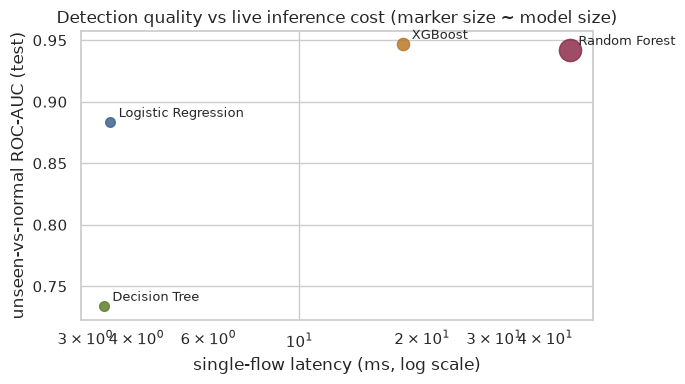

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for _, r in compute_tbl.iterrows():
    ax.scatter(r.single_flow_ms, r.unseen_auc, s=40 + r.model_size_kb ** 0.5 * 4, color=COLORS[r.model], alpha=.85)
    ax.annotate(r.model, (r.single_flow_ms, r.unseen_auc), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("single-flow latency (ms, log scale)"); ax.set_ylabel("unseen-vs-normal ROC-AUC (test)")
ax.set_title("Detection quality vs live inference cost (marker size ~ model size)")
fig.tight_layout(); cf.save_figure(fig, "additional", "compute_vs_performance"); plt.show()

## 7. Actual vs predicted attacks per group

For each group of test flows, the number of actual attacks next to the number each model flags as an attack, at threshold 0.5 and at the 1 / 2 / 5% test-FPR operating points. In the *Normal* group every flagged flow is a false alarm.

In [11]:
p0 = preds["Logistic Regression"]
GROUPS = {"Normal": (p0.y_true == 0).to_numpy(),
          "DoS": (p0.attack_category == "DoS").to_numpy(), "Probe": (p0.attack_category == "Probe").to_numpy(),
          "R2L": (p0.attack_category == "R2L").to_numpy(), "U2R": (p0.attack_category == "U2R").to_numpy(),
          "Unseen types": ((p0.y_true == 1) & p0.is_unseen).to_numpy()}
avp_rows = []
for name in MODELS:
    p = preds[name]
    s, y = p.y_prob.to_numpy(), p.y_true.to_numpy()
    ops = {"threshold_0.5": cf.THRESHOLD, **{cf.budget_key(b): cf.threshold_for_fpr(s[y == 0], b) for b in cf.FPR_BUDGETS}}
    for op, t in ops.items():
        for g, m in GROUPS.items():
            avp_rows.append({"model": name, "operating_point": op, "group": g, "group_size": int(m.sum()),
                             "actual_attacks": int((y[m] == 1).sum()), "predicted_attacks": int((s[m] > t).sum())})
avp = pd.DataFrame(avp_rows)
cf.save_table(avp, "actual_vs_predicted")
avp[avp.operating_point == "threshold_0.5"].pivot(index="group", columns="model", values="predicted_attacks").loc[list(GROUPS)]

model,Decision Tree,Logistic Regression,Random Forest,XGBoost
group,,,,
Normal,290,703,264,250
DoS,5798,5672,5923,5885
Probe,2223,1855,1819,1981
R2L,150,64,149,294
U2R,5,13,7,6
Unseen types,1311,1108,923,1062


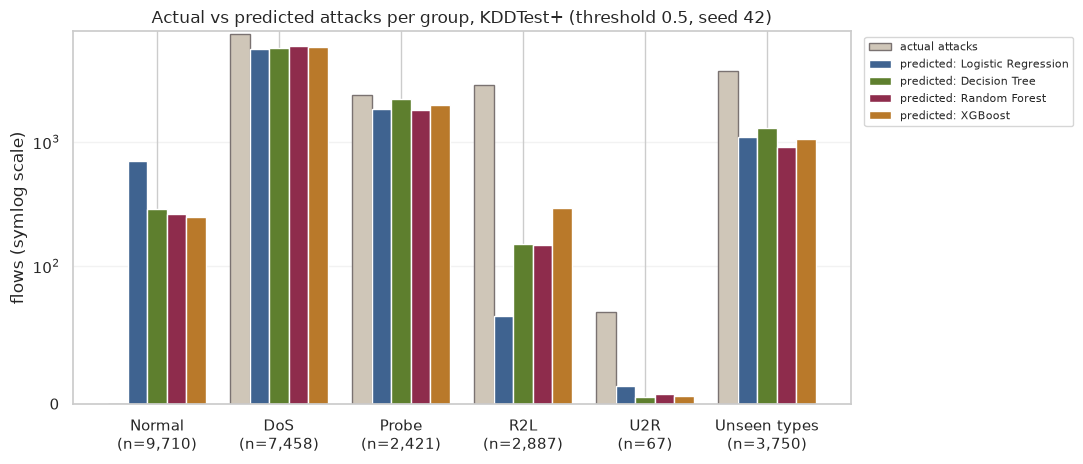

In [12]:
sub = avp[avp.operating_point == "threshold_0.5"]
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(len(GROUPS)), 0.16
actual = [sub[sub.group == g].actual_attacks.iloc[0] for g in GROUPS]
ax.bar(x - 2 * w, actual, w, color="#cfc6b8", edgecolor="#7a7271", label="actual attacks")
for j, name in enumerate(MODELS):
    vals = [sub[(sub.group == g) & (sub.model == name)].predicted_attacks.iloc[0] for g in GROUPS]
    ax.bar(x + (j - 1) * w, vals, w, color=COLORS[name], label=f"predicted: {name}")
ax.set_xticks(x, [f"{g}\n(n={GROUPS[g].sum():,})" for g in GROUPS]); ax.set_ylabel("flows (symlog scale)"); ax.set_yscale("symlog", linthresh=100)
ax.set_title("Actual vs predicted attacks per group, KDDTest+ (threshold 0.5, seed 42)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); cf.save_figure(fig, "additional", "actual_vs_predicted"); plt.show()

## 8. Save

In [13]:
out = {
    "note": ("Known-attack CV uses evaluation-only fold models with the seed-42 tuned hyperparameters; the saved final models "
             "and all KDDTest+ results are unchanged. FPR at 95% recall uses the saved seed-42 test predictions."),
    "seed": cf.SEED, "cv": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42) on KDDTrain+",
    "known_cv": known,
    "known_vs_unseen_gap": gap.set_index("model").to_dict(orient="index"),
    "fpr_at_95_recall": fpr95.set_index("model").to_dict(orient="index"),
    "known_roc": {"fpr_grid_pct": [round(float(x) * 100, 2) for x in FPR_GRID], "recall_pct": known_roc},
    "missed_records": {"key_features": KEY_FEATURES, "normal_reference": normal_ref, "records": records},
    "compute": {"hardware": hardware, "system": system, "per_model": compute},
    "actual_vs_predicted": avp_rows,
}
(cf.METRICS_DIR / "additional_evaluation.json").write_text(json.dumps(out, indent=2, default=str))
print("saved results/metrics/additional_evaluation.json")

saved results/metrics/additional_evaluation.json
